# 11. Structured Duplicate Verification & Evidence Auditing
**Project:** AI-Powered Student Achievement Intelligence Platform  
**Member Role:** Member 1 — NLP & Semantic Intelligence Engineer  
**Dataset Release:** `achievement_dataset_v1.0.1` (FROZEN)  
**Objective:** Implement and demonstrate a multi-stage duplicate verification pipeline combining dense Sentence Transformer candidate retrieval with explicit structured evidence verification to reliably distinguish genuine duplicates from semantically similar hard negatives.

## 1. Environment & Module Imports
We import system libraries, Sentence Transformers, and our certified `duplicate_detection` module.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Ensure src is importable
repo_root = Path(".").resolve()
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

from src.nlp.embedding import load_embedding_model, generate_embeddings, compute_pairwise_cosine_similarity
from src.nlp.duplicate_detection import (
    DuplicateDecision,
    FieldStatus,
    FieldComparison,
    DuplicateVerificationResult,
    compare_field,
    extract_entities_from_text,
    verify_duplicate_candidate,
    batch_verify_duplicate_pairs,
)

print("Modules successfully imported.")

Modules successfully imported.


## 2. Dataset Inspection & Structured Metadata Audit
We inspect the available structured fields across `achievement_classification_dataset.csv` and `achievement_duplicate_pairs.csv`.

In [2]:
main_df = pd.read_csv("data/processed/achievement_classification_dataset.csv")
pairs_df = pd.read_csv("data/annotations/achievement_duplicate_pairs.csv")

print(f"Primary Dataset: {len(main_df)} records, {len(main_df.columns)} columns.")
print(f"Duplicate Benchmark: {len(pairs_df)} pairs across splits: {dict(pairs_df['split'].value_counts())}")

# Audit metadata null rates
structured_cols = ["achievement_id", "category", "domain", "event_name", "organization", "achievement_date", "rank", "evidence_id"]
print("\nStructured Field Null Audit:")
for c in structured_cols:
    nulls = main_df[c].isna().sum()
    print(f"  {c:<18}: {nulls:>5} nulls ({nulls/len(main_df):.1%})")

Primary Dataset: 1540 records, 26 columns.
Duplicate Benchmark: 300 pairs across splits: {'train': np.int64(210), 'validation': np.int64(46), 'test': np.int64(44)}

Structured Field Null Audit:
  achievement_id    :     0 nulls (0.0%)
  category          :     0 nulls (0.0%)
  domain            :     0 nulls (0.0%)
  event_name        :   220 nulls (14.3%)
  organization      :     0 nulls (0.0%)
  achievement_date  :   193 nulls (12.5%)
  rank              :   660 nulls (42.9%)
  evidence_id       :  1540 nulls (100.0%)


## 3. Stage 1 — Dense Candidate Retrieval
We evaluate the role of dense semantic retrieval using `all-MiniLM-L6-v2`. Semantic similarity serves as a high-recall candidate filter, but NEVER declares a duplicate on its own.

In [3]:
model = load_embedding_model("sentence-transformers/all-MiniLM-L6-v2")

# Compute cosine similarities for validation split
val_pairs = pairs_df[pairs_df["split"] == "validation"].copy().reset_index(drop=True)
val_e1 = generate_embeddings(val_pairs["text_1"].tolist(), model=model)
val_e2 = generate_embeddings(val_pairs["text_2"].tolist(), model=model)
val_sims = compute_pairwise_cosine_similarity(val_e1, val_e2)
val_pairs["cosine_similarity"] = val_sims

print(f"Validation Pairs: {len(val_pairs)}")
print(f"True Duplicates (label=1) Mean Sim: {val_sims[val_pairs['duplicate_label'] == 1].mean():.4f}")
print(f"Hard Negatives   (label=0) Mean Sim: {val_sims[val_pairs['duplicate_label'] == 0].mean():.4f}")

# Candidate Retrieval Recall at varying cutoffs
for tau in [0.40, 0.45, 0.50, 0.55, 0.60]:
    passed = val_sims >= tau
    recall = (passed & (val_pairs["duplicate_label"] == 1)).sum() / (val_pairs["duplicate_label"] == 1).sum()
    pruned = (~passed).sum() / len(val_pairs)
    print(f"  Retrieval Threshold tau={tau:.2f} -> Candidate Recall: {recall:.1%}, Pruned Pairs: {pruned:.1%}")

Validation Pairs: 46
True Duplicates (label=1) Mean Sim: 0.6858
Hard Negatives   (label=0) Mean Sim: 0.5523
  Retrieval Threshold tau=0.40 -> Candidate Recall: 82.6%, Pruned Pairs: 26.1%
  Retrieval Threshold tau=0.45 -> Candidate Recall: 82.6%, Pruned Pairs: 30.4%
  Retrieval Threshold tau=0.50 -> Candidate Recall: 82.6%, Pruned Pairs: 32.6%
  Retrieval Threshold tau=0.55 -> Candidate Recall: 82.6%, Pruned Pairs: 39.1%
  Retrieval Threshold tau=0.60 -> Candidate Recall: 73.9%, Pruned Pairs: 45.7%


## 4. Stage 2 — Structured Evidence Comparison
We demonstrate how individual structured fields are compared. Crucially, missing values are NEVER treated as matches.

In [4]:
# Demonstrate strict missing value handling
comp_missing = compare_field("student_id", None, "STU-123")
print("Missing Field Comparison:")
print(f"  Status: {comp_missing.status.value}")
print(f"  Note: {comp_missing.note}")

# Demonstrate rank contradiction
comp_rank = compare_field("rank", "1st Place", "Runner-Up", is_rank=True)
print("\nRank Contradiction Comparison:")
print(f"  Status: {comp_rank.status.value}")
print(f"  Note: {comp_rank.note}")

# Demonstrate year contradiction
comp_year = compare_field("year", "2022-04-10", "2023-04-12", is_year=True)
print("\nYear Contradiction Comparison:")
print(f"  Status: {comp_year.status.value}")
print(f"  Note: {comp_year.note}")

Missing Field Comparison:
  Status: MISSING_ONE
  Note: Field 'student_id' is missing in record 1 (present value: 'stu-123'). Cannot assume match.

Rank Contradiction Comparison:
  Status: CONFLICT
  Note: Field 'rank' conflicts: 'RANK_1_WINNER' vs 'RANK_2_RUNNER_UP'.

Year Contradiction Comparison:
  Status: CONFLICT
  Note: Field 'year' conflicts: '2022' vs '2023'.


## 5. Stage 3 & 4 — Multi-Stage Decision System & Explanation Walkthrough
We run the complete verification engine across four representative test cases: exact duplicate, hard negative with rank conflict, hard negative with year conflict, and ambiguous record.

In [5]:
# Case 1: Genuine Duplicate (Paraphrase)
c1_r1 = {"achievement_id": "ACH-001", "achievement_text": "Won 1st place in Smart India Hackathon 2023.", "event_name": "Smart India Hackathon", "rank": "1st Place", "achievement_date": "2023-08-15"}
c1_r2 = {"achievement_id": "ACH-001_V2", "achievement_text": "Secured 1st place at Smart India Hackathon in 2023.", "event_name": "Smart India Hackathon", "rank": "1st Place", "achievement_date": "2023-08-15"}
res1 = verify_duplicate_candidate(c1_r1, c1_r2, cosine_similarity=0.88)
print(f"Case 1 Decision: {res1.decision.value} (Confidence: {res1.confidence:.2f})")
print(f"Explanation: {res1.explanation}\n")

# Case 2: Hard Negative (Same event, different ranks)
c2_r1 = {"achievement_id": "ACH-010", "achievement_text": "Won 1st place in Smart India Hackathon 2023.", "event_name": "Smart India Hackathon", "rank": "1st Place", "achievement_date": "2023-08-15"}
c2_r2 = {"achievement_id": "ACH-011", "achievement_text": "Secured Runner-Up in Smart India Hackathon 2023.", "event_name": "Smart India Hackathon", "rank": "Runner-Up", "achievement_date": "2023-08-15"}
res2 = verify_duplicate_candidate(c2_r1, c2_r2, cosine_similarity=0.76)
print(f"Case 2 Decision: {res2.decision.value} (Confidence: {res2.confidence:.2f})")
print(f"Explanation: {res2.explanation}\n")

# Case 3: Hard Negative (Same event, different years)
c3_r1 = {"achievement_id": "ACH-020", "achievement_text": "Gold medalist in National Athletics Meet (2022).", "event_name": "National Athletics Meet", "rank": "Gold Medal", "achievement_date": "2022-03-10"}
c3_r2 = {"achievement_id": "ACH-021", "achievement_text": "Gold medalist in National Athletics Meet (2023).", "event_name": "National Athletics Meet", "rank": "Gold Medal", "achievement_date": "2023-03-12"}
res3 = verify_duplicate_candidate(c3_r1, c3_r2, cosine_similarity=0.84)
print(f"Case 3 Decision: {res3.decision.value} (Confidence: {res3.confidence:.2f})")
print(f"Explanation: {res3.explanation}\n")

# Case 4: Ambiguous Candidate (Missing key identifiers)
c4_r1 = {"achievement_id": "ACH-030", "achievement_text": "Presented workshop on Robotics."}
c4_r2 = {"achievement_id": "ACH-031", "achievement_text": "Attended technical hands-on Robotics session."}
res4 = verify_duplicate_candidate(c4_r1, c4_r2, cosine_similarity=0.62)
print(f"Case 4 Decision: {res4.decision.value} (Confidence: {res4.confidence:.2f})")
print(f"Explanation: {res4.explanation}")

Case 1 Decision: DUPLICATE (Confidence: 0.88)
Explanation: Verified duplicate: High semantic similarity (0.88) corroborated by matching structured evidence: Placement rank matches: '1st Place'.; Achievement year matches: '2023-08-15'.; Event name matches: 'Smart India Hackathon'..

Case 2 Decision: DISTINCT (Confidence: 0.90)
Explanation: Structured verification identified 1 contradiction(s): Placement rank conflict: '1st Place' vs 'Runner-Up'.. Factual contradictions refute duplicate identity despite semantic similarity.

Case 3 Decision: DISTINCT (Confidence: 0.90)
Explanation: Structured verification identified 1 contradiction(s): Achievement year conflict: '2022-03-10' vs '2023-03-12'. Distinct instances across years.. Factual contradictions refute duplicate identity despite semantic similarity.

Case 4 Decision: REVIEW_REQUIRED (Confidence: 0.50)
Explanation: Candidate passed retrieval (similarity: 0.6200), but lacks conclusive structured evidence. Missing fields: Student identity

## 6. Decision Breakdown Visualization
We evaluate the structured verification system on the validation split and visualize the resulting decision breakdown.

Validation Split Decision Breakdown:
DISTINCT     27
DUPLICATE    19
Name: count, dtype: int64


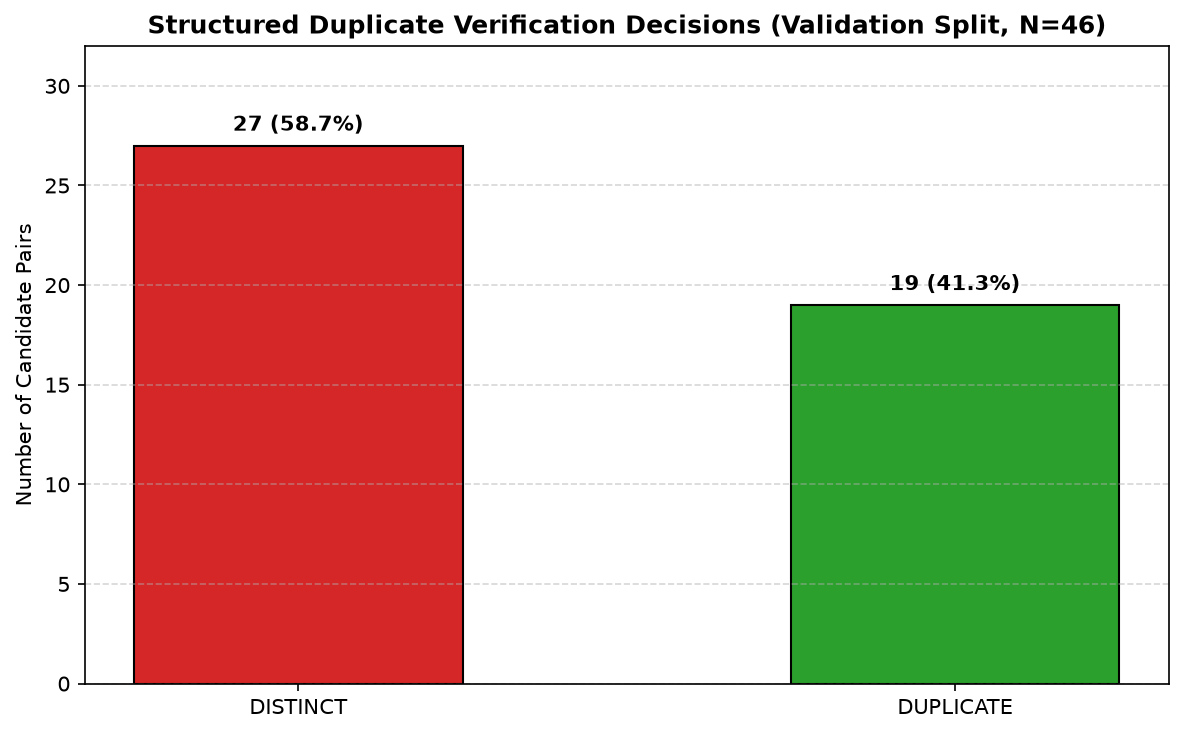

In [6]:
val_results = batch_verify_duplicate_pairs(
    val_pairs, main_dataset_df=main_df, cosine_similarities=val_sims,
    retrieval_threshold=0.50, high_similarity_threshold=0.70
)

decisions = [r.decision.value for r in val_results]
val_pairs["structured_decision"] = decisions

counts = pd.Series(decisions).value_counts()
print("Validation Split Decision Breakdown:")
print(counts)

fig, ax = plt.subplots(figsize=(8, 5))
colors = ["#2ca02c" if d == "DUPLICATE" else "#d62728" if d == "DISTINCT" else "#ff7f0e" for d in counts.index]
bars = ax.bar(counts.index, counts.values, color=colors, edgecolor="black", width=0.5)

for bar in bars:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width() / 2, yval + 0.5, f"{int(yval)} ({yval/len(val_pairs):.1%})", ha="center", va="bottom", fontweight="bold")

ax.set_title("Structured Duplicate Verification Decisions (Validation Split, N=46)", fontsize=12, fontweight="bold")
ax.set_ylabel("Number of Candidate Pairs")
ax.set_ylim(0, max(counts.values) + 5)
ax.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()